# Лабораторная работа 1 на Office-Home

Тема ВКР: **Сравнительный анализ методов выравнивания распределений для адаптации домена в задачах компьютерного зрения**.

Анализ результатов сравнения мультимодальных моделей и методов адаптации домена. Первичные ответы моделей сохранены в `results/raw`; код экспериментов находится в `src/benchmark.py`, `src/adaptation.py` и `src/train_lora.py`.

In [1]:
from pathlib import Path
import json, csv, hashlib
ROOT = Path.cwd()
assert (ROOT / 'configs/experiment.json').exists(), 'Откройте notebook из корня проекта'
def read_json(path): return json.loads((ROOT / path).read_text())
def read_csv(path):
    with (ROOT / path).open(encoding='utf-8-sig') as f: return list(csv.DictReader(f))
print('Наблюдений в корпусе:', read_json('data/download_metadata.json')['rows_decoded'])
print('Выбранная модель:', read_json('results/selection.json')['model'])

Наблюдений в корпусе: 15588
Выбранная модель: qwen25_3000


## Данные и отсутствие утечки
Полный корпус прошёл потоковый аудит; разбиение зафиксировано до сравнения. Дубликаты объединялись до разбиения. Все показатели ниже получены из сохранённого аудита.

In [2]:
audit = read_json('data/download_metadata.json')
print('Изображений в корпусе:', audit['rows_decoded'])
print('Домены:', audit['domain_counts'])
print('Размеры частей:', audit['split_counts'])
print('Точные пары:', audit['exact_duplicate_pairs'])
print('Кандидаты похожих пар:', audit['near_duplicate_candidate_pairs'])
print('Ошибок чтения:', len(audit['errors']))
manifest = read_json('data/manifest.json')
groups = {}
for r in manifest:
    assert groups.setdefault(r['group'], r['split']) == r['split']
print('Пересечений групп между частями нет')

Изображений в корпусе: 15588
Домены: {'Art': 2427, 'Clipart': 4365, 'Product': 4439, 'Real_World': 4357}
Размеры частей: {'source_train': 520, 'validation': 130, 'target_adapt': 195, 'test': 130, 'new_slice': 130, 'external': 130}
Точные пары: 412
Кандидаты похожих пар: 1041
Ошибок чтения: 0
Пересечений групп между частями нет


## Единый протокол
40 новых токенов, жадная генерация, строгий JSON; zero-shot и три фиксированных source-примера. Invalid считается ошибкой, без исправлений. Калибровка — по текстовой уверенности среди валидных ответов. Полный текст инструкции доступен в `configs/prompt_main.txt`.

Численная ошибка Qwen float16/MPS подтверждена на source_train и исправлена штатной точностью bfloat16. 156 технически некорректных ответов исключены и сохранены в `logs/invalid_runs`; изменение зарегистрировано в `configs/runtime_amendment.json`. Остальные модели используют float16. Различие точности ограничивает интерпретацию latency.

In [3]:
cfg = read_json('configs/experiment.json')
for model in cfg['models']: print(model['key'], model['repo'])
print('SHA256 протокола:', hashlib.sha256((ROOT/'configs/experiment.json').read_bytes()).hexdigest())
print('Правило выбора:', cfg['selection'])

smol256 HuggingFaceTB/SmolVLM-256M-Instruct
smol500 HuggingFaceTB/SmolVLM-500M-Instruct
smol2_500 HuggingFaceTB/SmolVLM2-500M-Video-Instruct
smol2_2200 HuggingFaceTB/SmolVLM2-2.2B-Instruct
llava500 llava-hf/llava-interleave-qwen-0.5b-hf
qwen2_2000 Qwen/Qwen2-VL-2B-Instruct
qwen25_3000 Qwen/Qwen2.5-VL-3B-Instruct
SHA256 протокола: 6b8846127338a766df274f5315a4194f183e2f4b7aaf84d15d25176f2a59fdd7
Правило выбора: {'invalid_rate_max': 0.1, 'weights': {'macro_f1': 0.6, 'one_minus_ece': 0.2, 'valid_rate': 0.1, 'speed_score': 0.1}, 'fallback': 'If no model satisfies invalid_rate_max, choose highest penalized score for exploratory application and explicitly label failure of validity gate.'}


## Фактические тестовые метрики
Доверительный интервал — 2000 стратифицированных bootstrap повторов. Малый тест ограничивает интерпретацию.

In [4]:
metrics = read_csv('results/model_metrics.csv')
print('model | mode | Macro-F1 | 95% CI | invalid rate | p50 seconds')
for r in metrics:
    if r['split']=='test' and r['variant']=='main':
        print(r['model'], r['mode'], round(float(r['macro_f1']),4), (r['macro_f1_ci_low'],r['macro_f1_ci_high']), r['invalid_rate'],r['latency_median_s'], sep=' | ')

model | mode | Macro-F1 | 95% CI | invalid rate | p50 seconds
llava500 | zero | 0.0005 | ('0.000508582326764145', '0.0005494505494505495') | 0.03076923076923077 | 2.1485192914988147
llava500 | few | 0.0005 | ('0.0004662004662004662', '0.0004662004662004662') | 0.0 | 9.269144520501868
qwen25_3000 | zero | 0.3749 | ('0.28920512820512817', '0.3969358974358973') | 0.6076923076923078 | 6.983672104495781
qwen25_3000 | few | 0.1324 | ('0.09286688311688313', '0.15144039972972012') | 0.0 | 14.452584500002558
qwen2_2000 | zero | 0.0557 | ('0.029487179487179487', '0.07051282051282051') | 0.7307692307692308 | 3.8040551874983066
qwen2_2000 | few | 0.105 | ('0.06710341864018335', '0.12681318681318682') | 0.2153846153846154 | 9.88951381300285
smol256 | zero | 0.0 | ('0.0', '0.0') | 1.0 | 1.3304108335005367
smol256 | few | 0.0 | ('0.0', '0.0') | 1.0 | 1.7492915415004973
smol2_2200 | zero | 0.1667 | ('0.13744912779528168', '0.18351854395604394') | 0.03076923076923077 | 8.177421499502088
smol2_2200 | fe

## Выбор и новые срезы
Модель выбирается по source validation, а не по максимуму test.

In [5]:
selection = read_json('results/selection.json')
print('Выбрана:', selection['model'], selection['mode'])
print('Порог валидности пройден:', selection['validity_gate_passed'])
test = [r for r in metrics if r['split']=='test' and r['variant']=='main']
chosen = next(r for r in test if r['model']==selection['model'] and r['mode']==selection['mode'])
best_test = max(test,key=lambda r:float(r['macro_f1']))
print('Выбранный режим на test:',chosen['macro_f1'])
print('Максимум на test:',best_test['model'],best_test['mode'],best_test['macro_f1'])
print('Test не изменяет выбор, сделанный по source validation')
for r in read_csv('results/application_metrics.csv'): print(r['domain'],r['n'],r['macro_f1'],r['invalid_rate'])

Выбрана: qwen25_3000 few
Порог валидности пройден: True
Выбранный режим на test: 0.13244868339207963
Максимум на test: qwen25_3000 zero 0.37487179487179484
Test не изменяет выбор, сделанный по source validation
Clipart 195 0.1527567056599315 0.0
Art 130 0.21600262984878368 0.0
Real_World 130 0.3970585389453314 0.0


## Вклад псевдометок в MMD и CORAL
Три seed, общий backbone, общий классификатор и source validation. Разброс между seed — SD, не доверительный интервал.

In [6]:
print(read_json('results/adaptation/pseudo_label_audit.json'))
for r in read_csv('results/adaptation/summary.csv'):
    print(r['split'],r['alignment'],r['pseudo_labels'],r['macro_f1_mean'],r['macro_f1_sd'])
print('Парный вклад псевдометок:')
for r in read_csv('results/adaptation/paired_effects.csv'): print(r)
print('Парный вклад выравнивания относительно none:')
for r in read_csv('results/adaptation/alignment_effects.csv'): print(r)

{'n_target_adapt': 195, 'accepted': 195, 'threshold': 0.7, 'model': 'qwen25_3000', 'mode': 'few', 'accepted_accuracy_for_evaluation_only': 0.13333333333333333, 'accepted_correct_for_evaluation_only': 26, 'predicted_classes_present': 26, 'most_frequent_predictions': [{'label_id': 43, 'class': 'Pencil', 'count': 152}, {'label_id': 27, 'class': 'Helmet', 'count': 5}, {'label_id': 23, 'class': 'Folder', 'count': 4}, {'label_id': 32, 'class': 'Laptop', 'count': 4}, {'label_id': 63, 'class': 'Trash_Can', 'count': 3}]}
test none False 0.25066759451374837 0.031978693671075316
test none True 0.12278349694251833 0.006461211475202978
test mmd False 0.2562231500693039 0.03387729058640655
test mmd True 0.11576990910324242 0.010523955785531084
test coral False 0.251434670574942 0.0296125544174101
test coral True 0.1154591087924421 0.002696063528933089
new_slice none False 0.3371713471713471 0.023984586473923254
new_slice none True 0.29153848046871306 0.030129395388866335
new_slice mmd False 0.341786

## LoRA как отдельное расширение
Обучается только языковой адаптер на source_train. Этот опыт не подменяет сравнение семи базовых моделей и не участвует задним числом в их выборе.

In [7]:
for r in read_csv('results/peft/metrics.csv'): print(r)
print(read_json('results/peft/paired_difference.json'))

{'n': '130', 'accuracy': '0.0', 'macro_f1': '0.0', 'weighted_f1': '0.0', 'mcc': '0.0', 'invalid_rate': '1.0', 'valid_n': '0', 'latency_median_s': '0.6811229169989019', 'latency_p95_s': '0.9354769624994332', 'peak_process_rss_gb': '2.492219392', 'balanced_accuracy': '0.0', 'ece': '', 'binary_brier': '', 'mode': 'zero', 'ci_low': '0.0', 'ci_high': '0.0'}
{'n': '130', 'accuracy': '0.0', 'macro_f1': '0.0', 'weighted_f1': '0.0', 'mcc': '-0.0009652581599987879', 'invalid_rate': '0.9923076923076923', 'valid_n': '1', 'latency_median_s': '1.8127803750003295', 'latency_p95_s': '1.9796892498506167', 'peak_process_rss_gb': '2.492219392', 'balanced_accuracy': '0.0', 'ece': '1.0', 'binary_brier': '1.0', 'mode': 'few', 'ci_low': '0.0', 'ci_high': '0.0'}
{'n': '130', 'accuracy': '0.007692307692307693', 'macro_f1': '0.0005215123859191656', 'weighted_f1': '0.0005215123859191656', 'mcc': '-0.009519247753975642', 'invalid_rate': '0.0', 'valid_n': '130', 'latency_median_s': '1.436271354001292', 'latency_p9

## Примеры ошибок
Исходные ответы сохраняются без редактирования. Причины ошибок нельзя устанавливать только по корреляции с фоном или длиной.

In [8]:
for r in read_json('results/ten_errors.json'):
    print('ID',r['id'],'true',r['true_class'],'predicted',r['predicted_class'],'model',r['model'])
    print(r['raw'])

ID 3629 true Alarm_Clock predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 4888 true Backpack predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 4850 true Batteries predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 2702 true Bed predicted Laptop model qwen25_3000
{"label_id": 32, "confidence": 1.0}
ID 3986 true Bike predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 5109 true Bottle predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 5307 true Bucket predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 4971 true Calculator predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 4883 true Candles predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}
ID 4862 true Chair predicted Pencil model qwen25_3000
{"label_id": 43, "confidence": 1.0}


## Графики

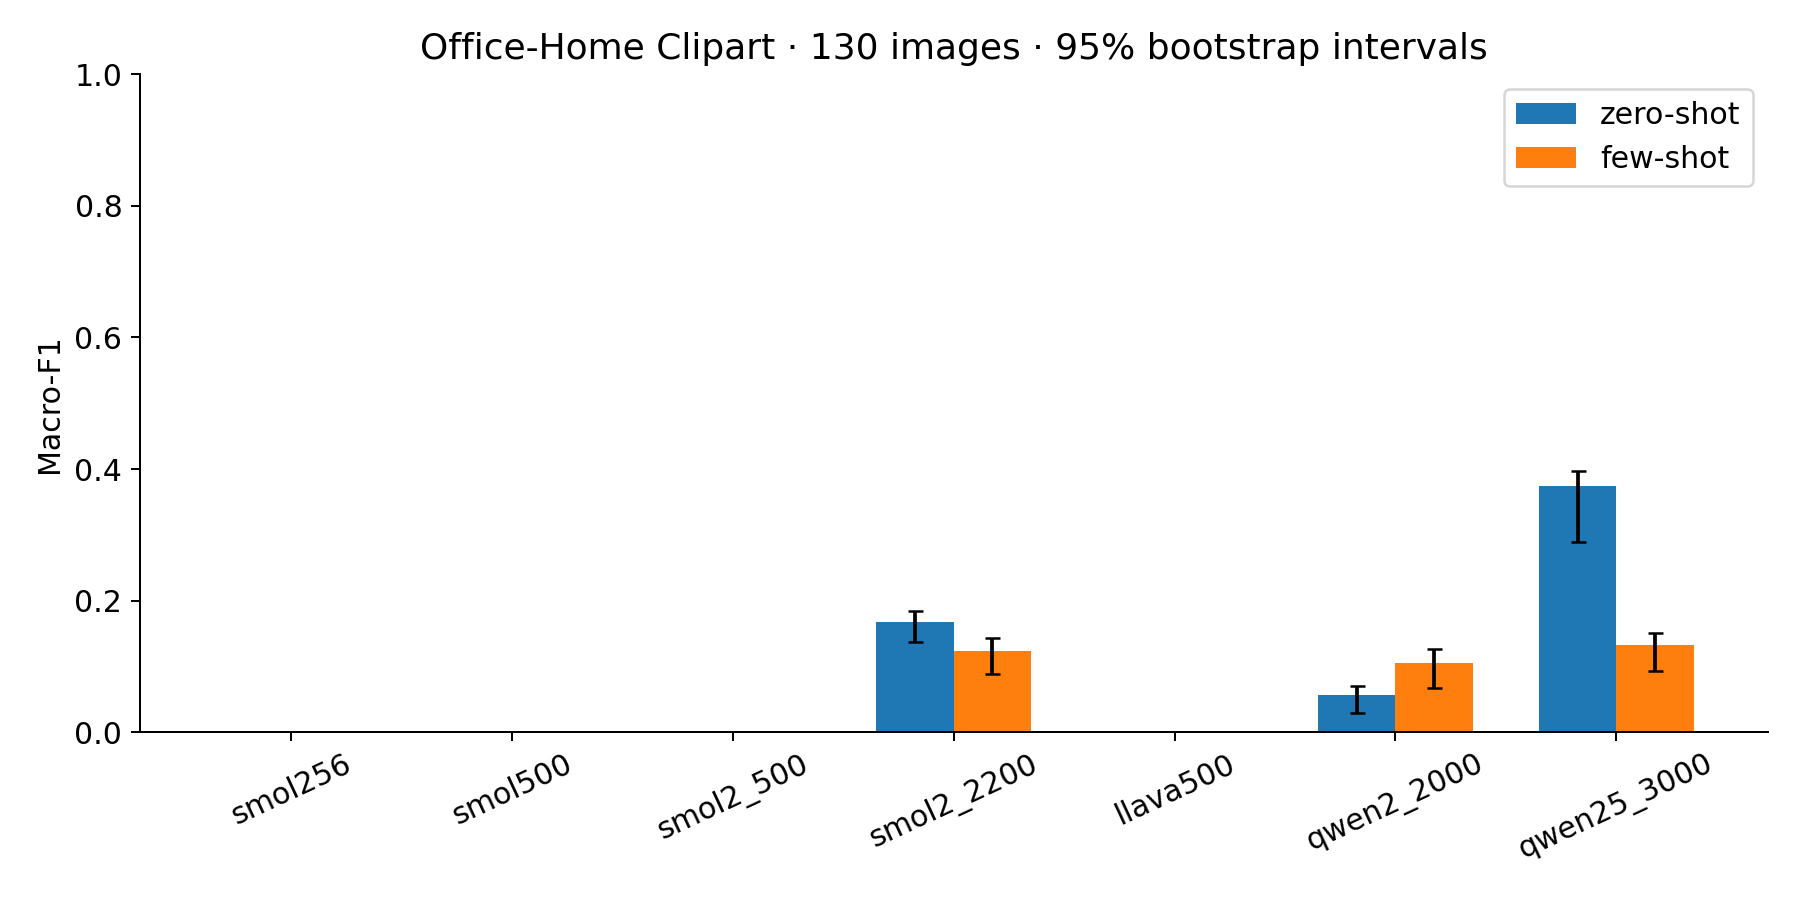

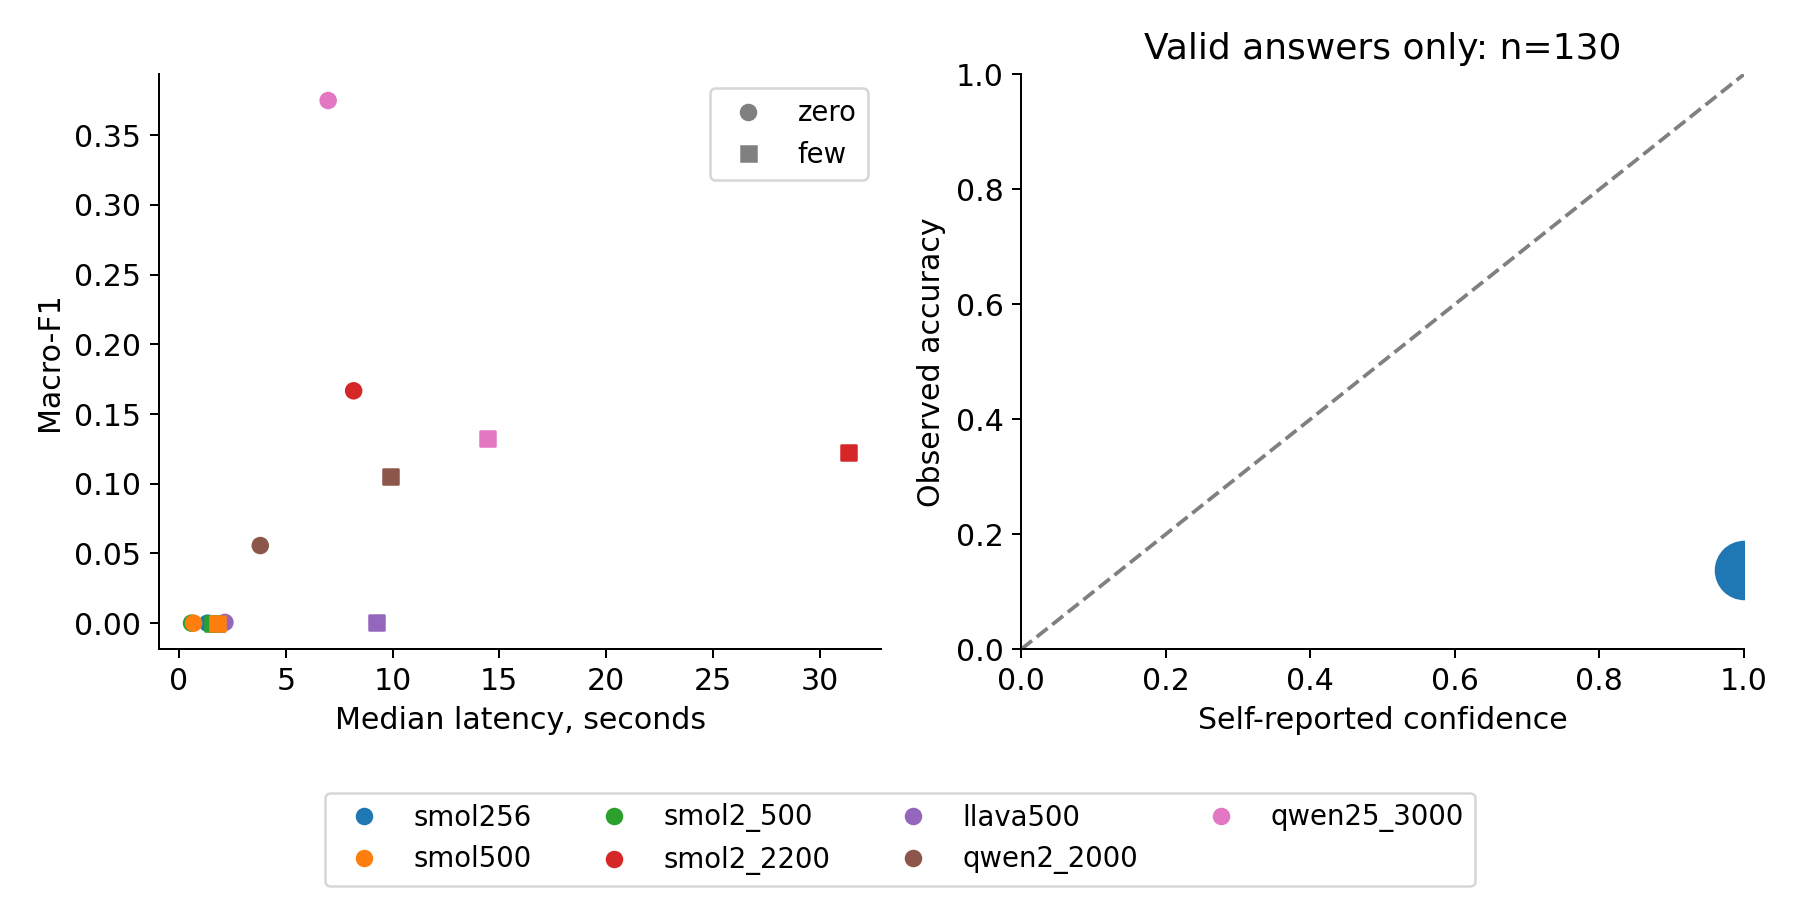

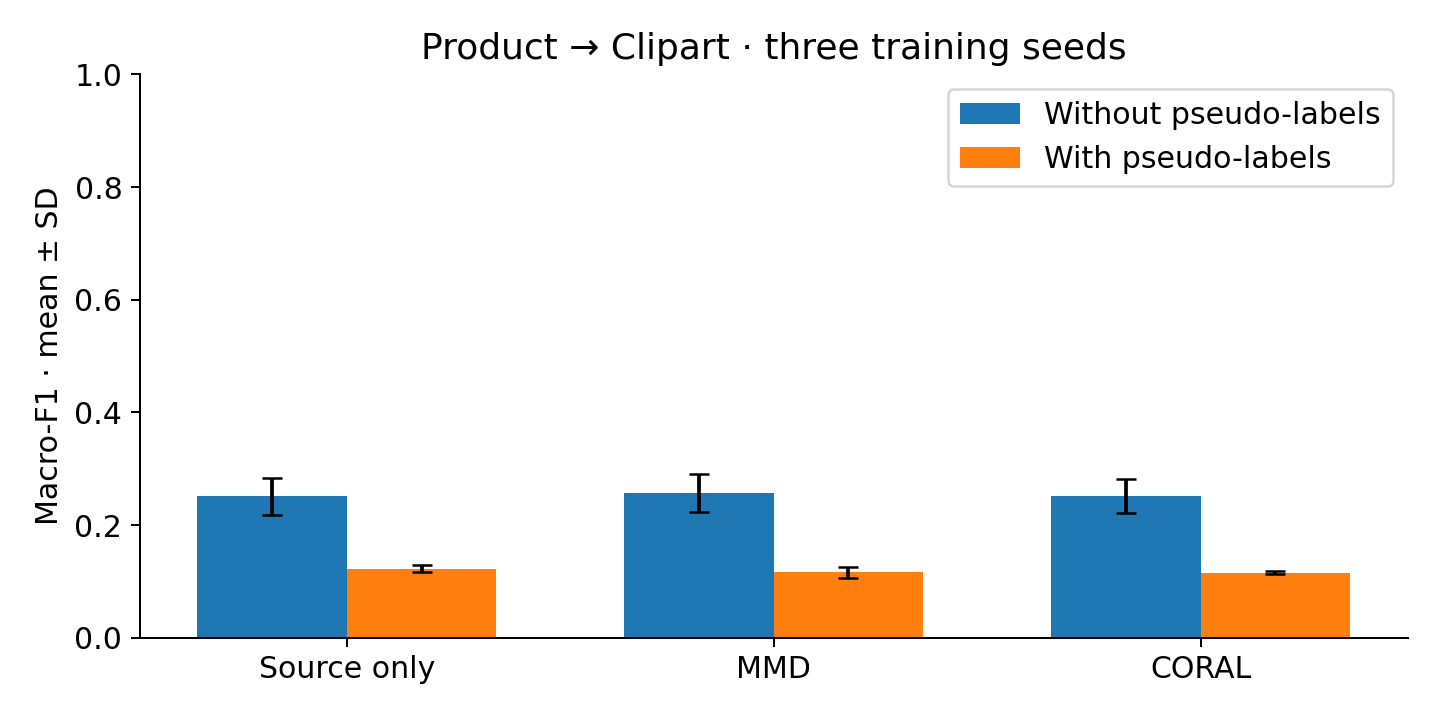

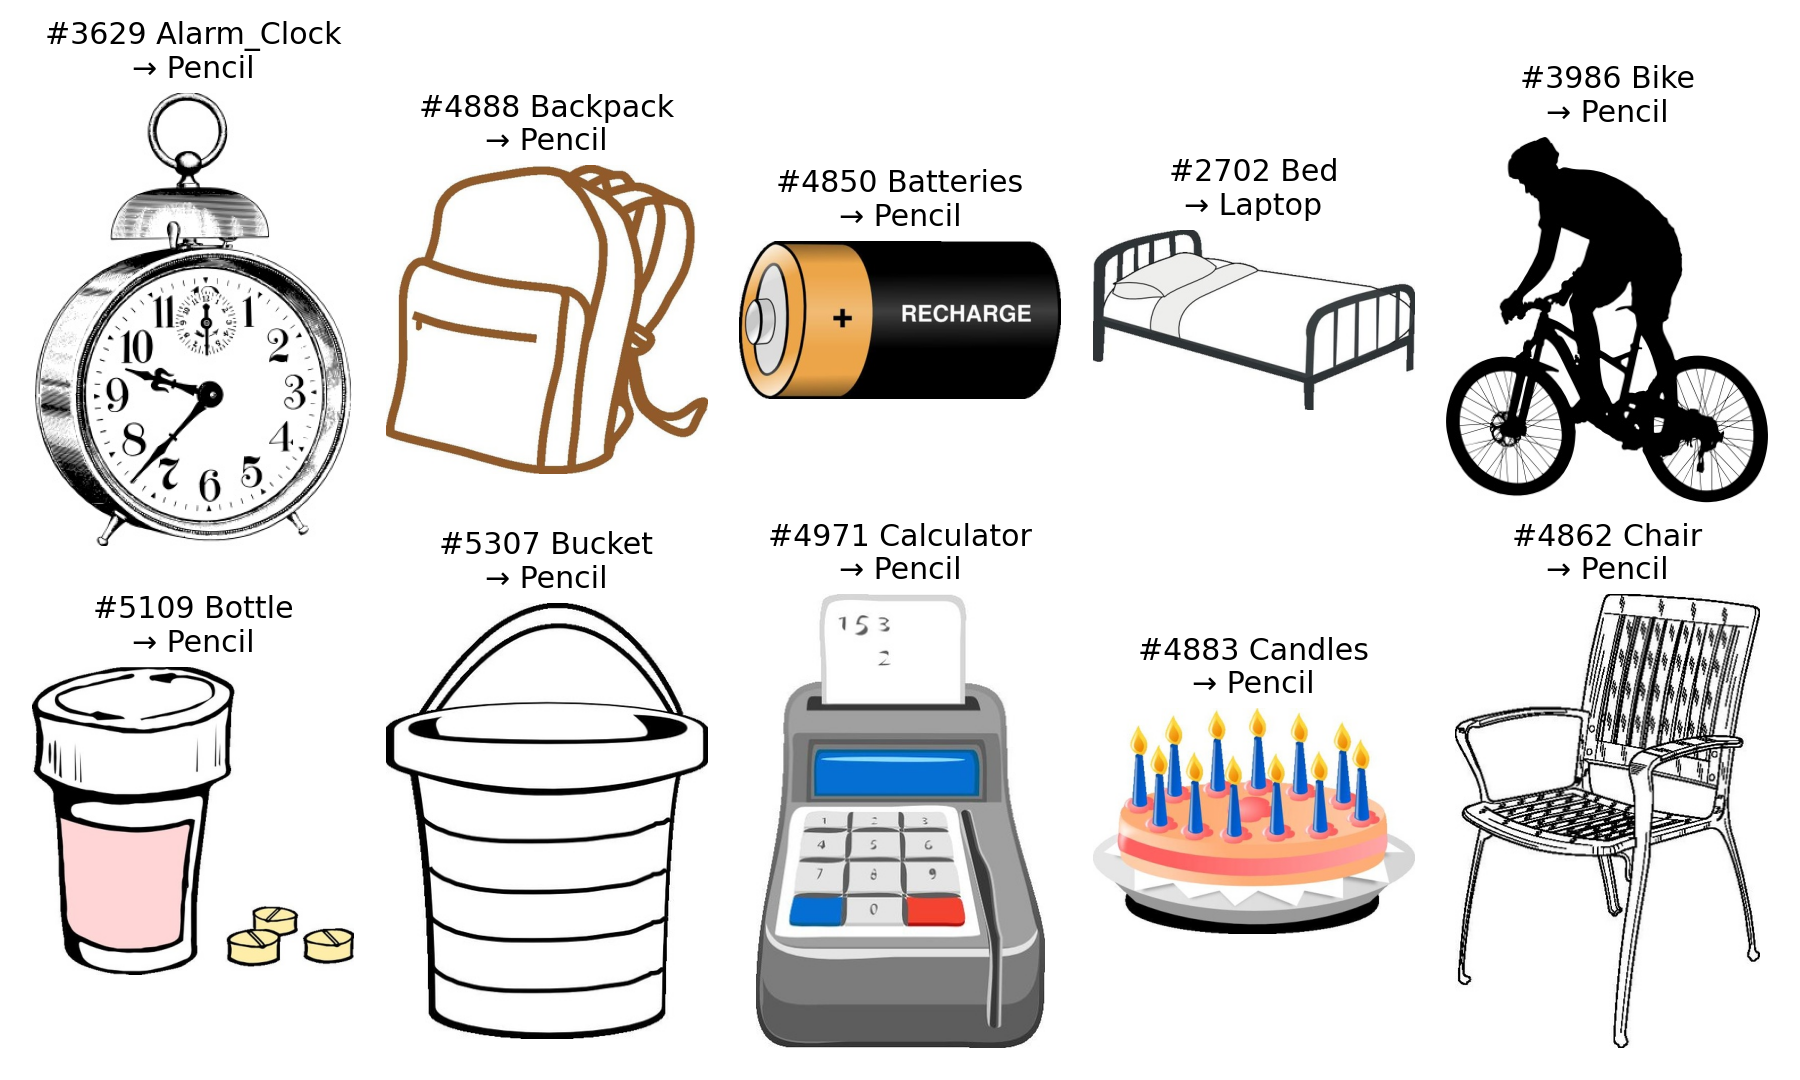

## Повторение вычислений
Для пересчёта анализа используйте `python src/summarize.py`, `python src/summarize_peft.py`, `python src/analyze_results.py`, `python src/verify_results.py`. Для повторного вывода моделей и обучения см. README. Скачанные веса удаляются после экспериментов, поэтому полный повтор требует их загрузки. Новый протокол должен записывать результаты в отдельный каталог.